In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

In [2]:
df = pd.read_csv("Phishing_website_dataset.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


In [3]:
if "index" in df.columns:
  df = df.drop(columns=["index"])

In [4]:
print(f"Dataset Shape: {df.shape}")

Dataset Shape: (11055, 31)


In [5]:
print("Missing values")
print(df.isnull().sum())

Missing values
having_IPhaving_IP_Address     0
URLURL_Length                  0
Shortining_Service             0
having_At_Symbol               0
double_slash_redirecting       0
Prefix_Suffix                  0
having_Sub_Domain              0
SSLfinal_State                 0
Domain_registeration_length    0
Favicon                        0
port                           0
HTTPS_token                    0
Request_URL                    0
URL_of_Anchor                  0
Links_in_tags                  0
SFH                            0
Submitting_to_email            0
Abnormal_URL                   0
Redirect                       0
on_mouseover                   0
RightClick                     0
popUpWidnow                    0
Iframe                         0
age_of_domain                  0
DNSRecord                      0
web_traffic                    0
Page_Rank                      0
Google_Index                   0
Links_pointing_to_page         0
Statistical_report          

In [6]:
# 2. FEATURE EXTRACTION & CREATION
print("Performing Feature Extraction and Creation...")
df_fe = df.copy()

Performing Feature Extraction and Creation...


In [7]:
# A. Feature Creation: Cumulative Security Risk Score
# Aggregates key vulnerability flags to represent overall threat exposure
core_threats = [
    "having_IPhaving_IP_Address",
    "Shortining_Service",
    "having_At_Symbol",
    "double_slash_redirecting",
    "Prefix_Suffix",
    "having_Sub_Domain",
    "SSLfinal_State",
]
df_fe["Security_Risk_Sum"] = df_fe[core_threats].sum(axis=1)

In [8]:
# B. Feature Extraction / Transformation: URL Complexity Index
# Combines structural URL anomalies and redirect mechanics into a single metric
df_fe["URL_Complexity_Index"] = (
    df_fe["URLURL_Length"]
    + df_fe["Abnormal_URL"]
    + df_fe["double_slash_redirecting"]
)

In [9]:
# C. Feature Creation: Non-linear Interaction Term
# Multiples server trust (SSL) with resource request behavior
df_fe["SSL_Request_Interaction"] = (
    df_fe["SSLfinal_State"] * df_fe["Request_URL"]
)

In [10]:
# D. Feature Extraction: Link Trust Ratio Index
# Combines link attributes in tags and anchor tags to gauge hyperlink safety
df_fe["Link_Trust_Ratio"] = (
    df_fe["URL_of_Anchor"] * df_fe["Links_in_tags"]
)
print(f"Dataset Shape after Feature Engineering: {df_fe.shape}")

Dataset Shape after Feature Engineering: (11055, 35)


In [11]:
X = df.drop(columns=["Result"])
y = df["Result"]

In [12]:
# Map target labels from {-1, 1} to standard binary {0, 1}
# 0: Legitimate Website, 1: Phishing Website
y = y.map({-1: 0, 1: 1})

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [14]:
print("Performing Feature Selection...")
selector_model = RandomForestClassifier(random_state=42)
selector_model.fit(X_train, y_train)

Performing Feature Selection...


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [15]:
# Get feature importances and sort them
importances = pd.Series(
    selector_model.feature_importances_, index=X.columns
).sort_values(ascending=False)

In [16]:
# Select the top N most important features (e.g., Top 10)
TOP_N = 10
selected_features = importances.head(TOP_N).index.tolist()

print(f"\nTop {TOP_N} Selected Features:")
for i, feat in enumerate(selected_features, 1):
  print(f"{i}. {feat} (Importance: {importances[feat]:.4f})")


Top 10 Selected Features:
1. SSLfinal_State (Importance: 0.3197)
2. URL_of_Anchor (Importance: 0.2500)
3. web_traffic (Importance: 0.0708)
4. having_Sub_Domain (Importance: 0.0695)
5. Links_in_tags (Importance: 0.0439)
6. Prefix_Suffix (Importance: 0.0379)
7. SFH (Importance: 0.0202)
8. Links_pointing_to_page (Importance: 0.0193)
9. Request_URL (Importance: 0.0177)
10. Domain_registeration_length (Importance: 0.0167)


In [17]:
X_train_reduced = X_train[selected_features]
X_test_reduced = X_test[selected_features]

In [18]:
# 3. Feature Scaling (For Logistic Regression and SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_reduced)
X_test_scaled = scaler.transform(X_test_reduced)

In [19]:
# 3. Define Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
}

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training SVM...


C:\Users\AKSHATA\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


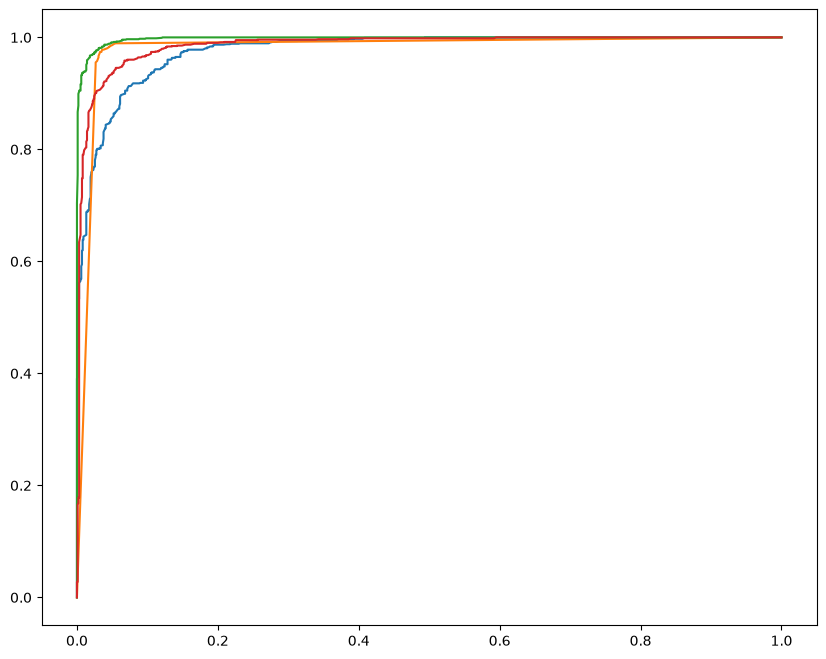

In [20]:
# 4. Train, Evaluate, and Store Metrics
evaluation_results = []
trained_models = {}
y_probs = {}

plt.figure(figsize=(10, 8))

for name, model in models.items():
  print(f"Training {name}...")

  # Train models using scaled data for Logistic Regression & SVM, raw data for Tree-based models
  if name in ["Logistic Regression", "SVM"]:
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
  else:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

  trained_models[name] = model
  y_probs[name] = y_prob

  # Compute Metrics
  acc = accuracy_score(y_test, y_pred)
  prec = precision_score(y_test, y_pred)
  rec = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  roc_auc = roc_auc_score(y_test, y_prob)

  evaluation_results.append({
      "Model": name,
      "Accuracy": acc,
      "Precision": prec,
      "Recall": rec,
      "F1-Score": f1,
      "ROC-AUC": roc_auc,
  })

  # Plot ROC Curve
  fpr, tpr, _ = roc_curve(y_test, y_prob)
  plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.4f})")

In [21]:
# 5. Display Performance Comparison Table
results_df = pd.DataFrame(evaluation_results)
print("\n" + "=" * 60)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 60)
print(results_df.to_string(index=False))
print("=" * 60)


MODEL PERFORMANCE COMPARISON
              Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
Logistic Regression  0.917232   0.911303 0.943136  0.926946 0.976890
      Decision Tree  0.971054   0.970185 0.978067  0.974110 0.980452
      Random Forest  0.974220   0.969600 0.984565  0.977025 0.997699
                SVM  0.941655   0.933176 0.964257  0.948462 0.986081


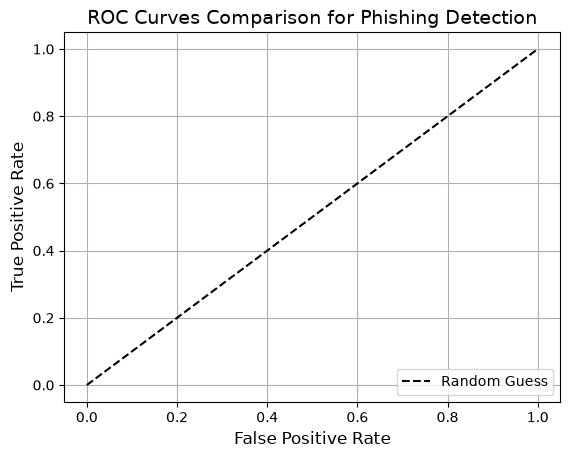

In [22]:
# Finalize ROC Curve Plot
plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("ROC Curves Comparison for Phishing Detection", fontsize=14)
plt.legend(loc="lower right")
plt.grid(True)
plt.savefig("roc_curves_comparison.png")
plt.show()


Best Performing Model: Random Forest


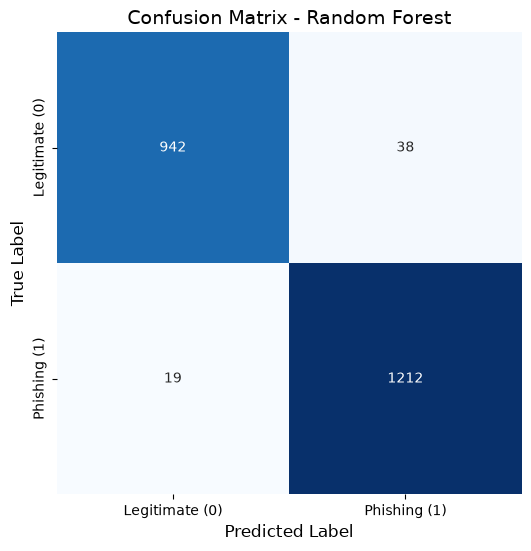

In [23]:
best_model_name = results_df.loc[results_df["F1-Score"].idxmax(), "Model"]
print(f"\nBest Performing Model: {best_model_name}")

best_model = trained_models[best_model_name]
if best_model_name in ["Logistic Regression", "SVM"]:
  best_preds = best_model.predict(X_test_scaled)
else:
  best_preds = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_preds)
plt.figure(figsize=(6, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Legitimate (0)", "Phishing (1)"],
    yticklabels=["Legitimate (0)", "Phishing (1)"],
)
plt.title(f"Confusion Matrix - {best_model_name}", fontsize=14)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.savefig("confusion_matrix_best_model.png")
plt.show()

In [24]:
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP): {tp}")

True Negatives (TN): 942
False Positives (FP): 38
False Negatives (FN): 19
True Positives (TP): 1212
